# EN3160 Assignment 03: Neural Networks

**Name:** [Perera H.A.J.I]
**Student ID / Index number:** [230477X]
**Date:** [19-10-2026]

## Task 1: Fully Connected Neural Network with Manual Backpropagation

Using GPU: NVIDIA GeForce RTX 4060 Laptop GPU
PyTorch CUDA version: 12.6


100%|██████████| 170M/170M [59:02<00:00, 48.1kB/s]   


Epoch 1/10, Loss: 1.8078
Epoch 2/10, Loss: 1.6768
Epoch 3/10, Loss: 1.6158
Epoch 4/10, Loss: 1.5710
Epoch 5/10, Loss: 1.5309
Epoch 6/10, Loss: 1.4962
Epoch 7/10, Loss: 1.4673
Epoch 8/10, Loss: 1.4402
Epoch 9/10, Loss: 1.4167
Epoch 10/10, Loss: 1.3957


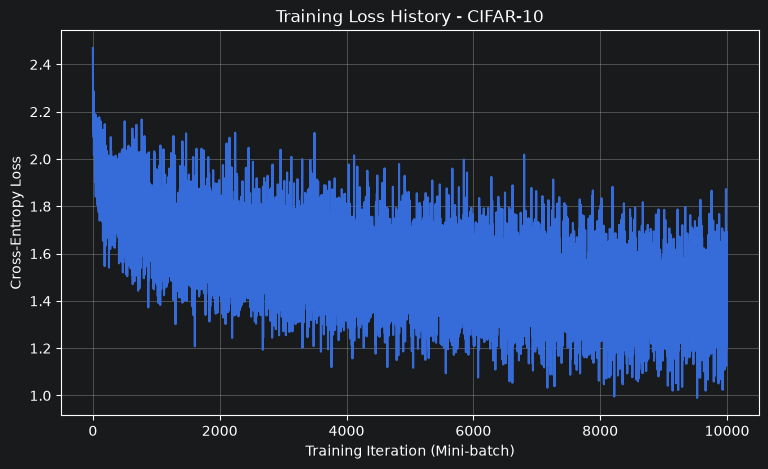

Training accuracy: 53.70%
Test accuracy: 47.93%


In [6]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
# Reproducibility
torch.manual_seed(42)
# GPU configuration
assert torch.cuda.is_available(), "CUDA is not available!"
device = torch.device("cuda:0")
print("Using GPU:", torch.cuda.get_device_name(0))
print("PyTorch CUDA version:", torch.version.cuda)
# 1. Dataloading
transform = transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5, 0.5, 0.5),(0.5, 0.5, 0.5))])
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data',train=True,download=True,transform=transform)
trainloader = torch.utils.data.DataLoader(trainset,batch_size=batch_size,shuffle=True,num_workers=0,pin_memory=True)
testset = torchvision.datasets.CIFAR10(root='./data',train=False,download=True,transform=transform)
testloader = torch.utils.data.DataLoader(testset,batch_size=batch_size,shuffle=False,num_workers=0,pin_memory=True)
classes = ('plane', 'car', 'bird', 'cat', 'deer','dog', 'frog', 'horse', 'ship', 'truck')
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size
H = 100            # Hidden layer size
K = 10             # Output size
# Initialize weights and biases
# Input -> Hidden layer
w1 = torch.randn(Din, H, device=device) * (1 / Din)**0.5
b1 = torch.zeros(H, device=device)
# Hidden -> Output layer
w2 = torch.randn(H, K, device=device) * (1 / H)**0.5
b2 = torch.zeros(K, device=device)
# Hyperparameters
iterations = 10
lr = 0.1
lr_decay = 0.9
reg = 0
loss_history = []
# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        Ntr = inputs.shape[0]
        # Flatten inputs
        x_train = inputs.view(Ntr, -1)
        # One-hot encoding
        y_train_onehot = nn.functional.one_hot(labels, K).float()
        # Forward pass - Hidden layer
        z1 = x_train.mm(w1) + b1
        h = torch.sigmoid(z1)
        # Forward pass - Output layer
        y_pred = h.mm(w2) + b2
        # Softmax and Cross-Entropy Loss
        log_probs = y_pred - torch.logsumexp(y_pred, dim=1, keepdim=True)
        probs = torch.exp(log_probs)
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * log_probs) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()
        # Backpropagation - Output layer
        dy_pred = (probs - y_train_onehot) / Ntr
        dw2 = h.t().mm(dy_pred) + 2 * reg * w2
        db2 = dy_pred.sum(dim=0)
        # Backpropagation - Hidden layer
        dh = dy_pred.mm(w2.t())
        dz1 = dh * h * (1 - h)
        dw1 = x_train.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)
        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2
    # Print loss for every epoch
    print(
        f"Epoch {t + 1}/{iterations}, "
        f"Loss: {running_loss / len(trainloader):.4f}"
    )
    # Learning rate decay
    lr *= lr_decay
# 4. Plotting the Loss History
plt.figure(figsize=(9, 5))
plt.plot(loss_history)
plt.title("Training Loss History - CIFAR-10")
plt.xlabel("Training Iteration (Mini-batch)")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)
plt.show()
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        # Forward pass - Hidden layer
        h = torch.sigmoid(x_train.mm(w1) + b1)
        # Forward pass - Output layer
        y_train_pred = h.mm(w2) + b2
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()
train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")
# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        # Forward pass - Hidden layer
        h = torch.sigmoid(x_test.mm(w1) + b1)
        # Forward pass - Output layer
        y_test_pred = h.mm(w2) + b2
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()
test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

### Task 1 – Results and Discussion
A fully connected neural network consisting of 100 hidden neurons with sigmoid activation was implemented for CIFAR-10 classification. The network was trained for 10 epochs using cross entropy loss and manually implemented backpropagation. The training loss decreased consistently from **1.8078 in the first epoch to 1.3957 in the final epoch** indicating that the network successfully learned useful patterns from the training data. Although the mini batch loss fluctuated during training, the average loss decreased steadily across epochs. The model achieved a **training accuracy of 53.70% and a test accuracy of 47.93%**. The difference of 5.77 percentage points suggests a moderate generalization gap with slightly lower performance on unseen images. The relatively limited classification accuracy can be attributed partly to the fully connected architecture. Flattening the images removes their explicit two dimensional spatial arrangement preventing the network from directly exploiting local image features in the way convolutional neural networks can. Overall, the results demonstrate successful implementation of a two layer neural network with sigmoid activation, cross entropy loss and manual backpropagation. The experiment also highlights the limitations of shallow fully connected networks for image classification tasks.

## Task 2: LeNet-5 vs Modern CNN on MNIST

[Add your implementation, experiments, comparison, and discussion here.]

## Task 3: ResNet-18 Transfer Learning

[Add your implementation, experiments, results, and discussion here.]